# Datathon 2026: Member 3 notebook
**Feature groups:** Anomalies · Accounts · Party details & tokens (plus load + QC for the whole team)

**How to run**
1. `pip install duckdb pandas pyarrow matplotlib scipy jupyter`
2. Put the CSV in `data/raw/` (or edit `CSV_PATH` below). If your file is tab-separated, set `DELIM = '\t'`.
3. If you hit *Out of Memory*: restart the kernel, lower `MEMORY` / `THREADS` in the setup cell, and run again (the parquet is reused).
4. Run all cells top to bottom. The first run converts the CSV to parquet (a few minutes); later runs reuse the parquet.
5. Every result table is saved to `outputs/tables/`, and every chart to `outputs/figures/`.

**Rules of this notebook**
- Full data is used everywhere (anomalies are rare, so sampling would leave too few rows). The only exception is control samples, which are marked as such.
- Nothing is deleted. Anomalies and outliers are kept and flagged.
- All times are UTC.
- Hypothesis IDs (A1…, AC1…, D1…) match `outputs/tables/hypotheses.csv`. After each section, update that file with ✅ held / ❌ rejected / ⚠️ partial.

## 0. Setup

In [1]:
import os, duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import chi2_contingency

CSV_PATH = os.environ.get("SWIFT_CSV", "data/raw/swift_umdac_datathon_2026_fictitious_payment_data.csv")
PARQUET  = os.environ.get("SWIFT_PARQUET", "data/processed/payments.parquet")
DELIM    = ","            # change to "\t" if the file is tab-separated
MEMORY   = os.environ.get("SWIFT_MEMORY", "4GB")   # about half your RAM: 4GB on 8 GB, 8GB on 16 GB
THREADS  = int(os.environ.get("SWIFT_THREADS", "4"))  # fewer threads = less memory
FIG, TAB = Path("outputs/figures"), Path("outputs/tables")
for d in [FIG, TAB, Path(PARQUET).parent, Path("tmp")]:
    d.mkdir(parents=True, exist_ok=True)

con = duckdb.connect("work.duckdb")       # on-disk database: helper tables live on disk, not in RAM
con.execute("SET TimeZone='UTC'")            # never skip: otherwise hours shift to your laptop's zone
con.execute(f"SET memory_limit='{MEMORY}'")
con.execute("SET temp_directory='tmp/'")         # big joins/sorts spill here instead of crashing
con.execute(f"SET threads={THREADS}")
con.execute("SET preserve_insertion_order=false")  # lets DuckDB stream results with less memory
pd.set_option("display.max_columns", 60, "display.width", 220, "display.float_format", "{:,.4f}".format)

def q(sql):
    """Run SQL and return a pandas DataFrame."""
    return con.sql(sql).df()

def save(df, name):
    """Save a result table to outputs/tables/<name>.csv and return it for display."""
    df.to_csv(TAB / f"{name}.csv", index=False)
    return df

APPENDIX_LABELS = ["ROMANCE_SCAM", "CEO_SCAM", "ACCOUNT_REPLACEMENT_SCAM", "FAT_FINGER_MISTAKE", "DUPLICATE_PAYMENT"]
APPX_SQL = ", ".join(f"'{a}'" for a in APPENDIX_LABELS)
print("DuckDB", duckdb.__version__)

DuckDB 2.0.0


## 1. Load: CSV → parquet (run once)
- Text columns contain line breaks inside quotes, so the CSV is read with explicit quoting and fixed column types. If types were guessed, one bad row could silently turn a numeric column into text.
- `DISCLAIMER` (1 non-empty value) is printed, then dropped. Quote it on the "Responsible data use" slide.
- Derived columns are added once here, so every later query (yours and your teammates') uses the same definitions.

In [2]:
COLS = {
    "DISCLAIMER": "VARCHAR", "EPOCH_SECONDS": "BIGINT", "CURRENCY_CODE": "VARCHAR", "USD_AMOUNT": "DOUBLE",
    "ORDERING_BIC8": "VARCHAR", "BENEFICIARY_BIC8": "VARCHAR", "BIC8_PATH": "VARCHAR", "TOTAL_DURATION": "BIGINT",
    "CONTINUITY_QFLAG": "VARCHAR", "CURRENCY_CONVERSION_COUNT": "INTEGER", "PARTICIPANT_COUNT": "INTEGER",
    "TRANSACTION_TYPE_CODE": "VARCHAR", "ORDERING_ACCOUNT": "VARCHAR", "BENEFICIARY_ACCOUNT": "VARCHAR",
    "ORDERING_DETAILS": "VARCHAR", "ORDERING_TOKENS": "VARCHAR", "BENEFICIARY_DETAILS": "VARCHAR",
    "BENEFICIARY_TOKENS": "VARCHAR", "ORDERING_TYPE": "VARCHAR", "BENEFICIARY_TYPE": "VARCHAR", "ANOMALY_TYPE": "VARCHAR",
}

def csv_source(parallel=True):
    cols = ", ".join(f"'{k}': '{v}'" for k, v in COLS.items())
    return (f"read_csv('{CSV_PATH}', header=true, delim='{DELIM}', quote='\"', escape='\"', "
            f"columns={{{cols}}}, max_line_size=10000000, parallel={str(parallel).lower()})")

DERIVED_SQL = r"""
COPY (
  SELECT * EXCLUDE (DISCLAIMER),
    row_number() OVER ()                                   AS rid,        -- stable row id
    to_timestamp(EPOCH_SECONDS)                            AS ts,         -- UTC
    substr(ORDERING_BIC8, 5, 2)                            AS o_cc,       -- sender bank country
    substr(BENEFICIARY_BIC8, 5, 2)                         AS b_cc,       -- receiver bank country
    ORDERING_TYPE || '2' || BENEFICIARY_TYPE               AS pair,       -- B2B / B2C / C2B / C2C
    coalesce(nullif(trim(ANOMALY_TYPE), ''), 'NONE')       AS anomaly,
    substr(ORDERING_BIC8, 5, 2) <> substr(BENEFICIARY_BIC8, 5, 2) AS cross_border,
    regexp_extract(ORDERING_TOKENS,    '<country_(?:code|name):([A-Z]{2})', 1) AS o_det_cc,   -- country written in details
    regexp_extract(BENEFICIARY_TOKENS, '<country_(?:code|name):([A-Z]{2})', 1) AS b_det_cc,
    trim(regexp_extract(replace(ORDERING_DETAILS,    chr(13), ''), '^/+([^\n]*)', 1)) AS o_det_acct, -- account line in details
    trim(regexp_extract(replace(BENEFICIARY_DETAILS, chr(13), ''), '^/+([^\n]*)', 1)) AS b_det_acct,
    regexp_replace(replace(BENEFICIARY_DETAILS, chr(13), ''), '^/[^\n]*\n?', '')      AS b_party_text -- details minus account line
  FROM __SRC__
) TO '__OUT__' (FORMAT parquet, COMPRESSION zstd)
"""

if not Path(PARQUET).exists():
    for parallel in (True, False):            # fall back to single-thread reading if quoted line breaks confuse the parallel reader
        try:
            src = csv_source(parallel)
            print("DISCLAIMER:", con.execute(f"SELECT DISCLAIMER FROM {src} WHERE DISCLAIMER IS NOT NULL LIMIT 1").fetchall())
            con.execute(DERIVED_SQL.replace("__SRC__", src).replace("__OUT__", PARQUET))
            print("Parquet written, parallel =", parallel)
            break
        except Exception as e:
            print("Load failed with parallel =", parallel, "->", str(e)[:300])
    else:
        raise RuntimeError("CSV could not be parsed. Check DELIM and the file path.")

con.execute(f"CREATE OR REPLACE VIEW p AS SELECT * FROM read_parquet('{PARQUET}')")
display(q("DESCRIBE p")[["column_name", "column_type"]].T)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
column_name,EPOCH_SECONDS,CURRENCY_CODE,USD_AMOUNT,ORDERING_BIC8,BENEFICIARY_BIC8,BIC8_PATH,TOTAL_DURATION,CONTINUITY_QFLAG,CURRENCY_CONVERSION_COUNT,PARTICIPANT_COUNT,TRANSACTION_TYPE_CODE,ORDERING_ACCOUNT,BENEFICIARY_ACCOUNT,ORDERING_DETAILS,ORDERING_TOKENS,BENEFICIARY_DETAILS,BENEFICIARY_TOKENS,ORDERING_TYPE,BENEFICIARY_TYPE,ANOMALY_TYPE,rid,ts,o_cc,b_cc,pair,anomaly,cross_border,o_det_cc,b_det_cc,o_det_acct,b_det_acct,b_party_text
column_type,BIGINT,VARCHAR,DOUBLE,VARCHAR,VARCHAR,VARCHAR,BIGINT,VARCHAR,INTEGER,INTEGER,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,BIGINT,TIMESTAMP WITH TIME ZONE,VARCHAR,VARCHAR,VARCHAR,VARCHAR,BOOLEAN,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR


In [3]:
# Parse check: numeric columns must have no NULLs, and the row count should be ~10,000,000
chk = q("""
SELECT count(*) AS rows, count(EPOCH_SECONDS) AS epoch_ok, count(USD_AMOUNT) AS amount_ok,
       min(ts) AS first_ts, max(ts) AS last_ts,
       count(DISTINCT CURRENCY_CODE) AS currencies, count(DISTINCT o_cc) AS sender_countries,
       sum((anomaly <> 'NONE')::INT) AS anomaly_rows
FROM p""")
display(chk)
assert chk.loc[0, "rows"] == chk.loc[0, "epoch_ok"] == chk.loc[0, "amount_ok"], "Some rows did not parse: check DELIM / quoting"

,rows,epoch_ok,amount_ok,first_ts,last_ts,currencies,sender_countries,anomaly_rows
0,10000000,10000000,10000000,2023-04-30 11:22:26+00:00,2023-07-31 09:56:01+00:00,155,228,"7,006.0000"


## 2. Quality control → issues log (rubric 3.1)
One row per check: what was found, the decision, and the reason. This table goes on the QC slide almost as-is.

In [4]:
display(save(q("SUMMARIZE p"), "qc_summarize_all_columns"))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,EPOCH_SECONDS,BIGINT,1682853746,1690797361,5119419,1686927373.7817295,2191913.66823333,1685173123,1687041648,1688631898,10000000,0.0000
1,CURRENCY_CODE,VARCHAR,AED,ZWL,151,None,None,None,None,None,10000000,0.0000
2,USD_AMOUNT,DOUBLE,0.01,15664132213.09,3441855,97204.10203820391,9909715.280074414,636.3086011410334,3673.080534836612,20018.19093707073,10000000,0.0000
3,ORDERING_BIC8,VARCHAR,0000ADA0,1136US30,8709,None,None,None,None,None,10000000,0.0000
4,BENEFICIARY_BIC8,VARCHAR,0000ADA0,1136US30,8632,None,None,None,None,None,10000000,0.0000
5,BIC8_PATH,VARCHAR,0000ADA0;...;...;0000NL20;0023ILI0;0001MQM0,1136US30;0313FRP0;0006LV20,4122510,None,None,None,None,None,10000000,0.0000
6,TOTAL_DURATION,BIGINT,2,21649,9468,771.5102084,1228.2022156000533,26,57,1109,10000000,0.0000
7,CONTINUITY_QFLAG,VARCHAR,N,Y,2,None,None,None,None,None,10000000,0.0000
8,CURRENCY_CONVERSION_COUNT,INTEGER,0,17,18,1.3430237,0.9446476223832116,1,1,2,10000000,0.0000
9,PARTICIPANT_COUNT,INTEGER,2,22,19,2.5815715,0.9592645007538686,2,2,3,10000000,0.0000


In [5]:
checks = [
 # (check, sql returning one value, decision, reason)
 ("Total rows", "SELECT count(*) FROM p", "Keep all", "Baseline count"),
 ("Normal rows (blank ANOMALY_TYPE)", "SELECT sum((anomaly='NONE')::INT) FROM p", "Blank = normal payment, recoded as 'NONE'", "Blank is a label, not missing data"),
 ("Exact duplicate rows (64-bit row hash)", f"SELECT count(*) - count(DISTINCT hash({', '.join(c for c in COLS if c != 'DISCLAIMER')})) FROM p",
      "Keep", "DUPLICATE_PAYMENT is a labelled behaviour; see section 4.3"),
 ("USD_AMOUNT <= 0", "SELECT sum((USD_AMOUNT <= 0)::INT) FROM p", "Flag only", "Would break log-amount analysis"),
 ("USD_AMOUNT min", "SELECT min(USD_AMOUNT) FROM p", "Keep", "Range check"),
 ("USD_AMOUNT max", "SELECT max(USD_AMOUNT) FROM p", "Keep, check if FAT_FINGER", "Extremes may be labelled errors"),
 ("Max amount row label", "SELECT arg_max(anomaly, USD_AMOUNT) FROM p", "-", "Is the largest amount a labelled anomaly?"),
 ("TOTAL_DURATION < 0", "SELECT sum((TOTAL_DURATION < 0)::INT) FROM p", "Flag only", "Impossible value"),
 ("Currency code not 3 letters", "SELECT sum((NOT regexp_full_match(CURRENCY_CODE, '[A-Z]{3}'))::INT) FROM p", "Flag only", "Format check"),
 ("BIC8 not 8 characters", "SELECT sum((length(ORDERING_BIC8) <> 8 OR length(BENEFICIARY_BIC8) <> 8)::INT) FROM p", "Flag only", "Country is read from BIC chars 5-6"),
 ("Party type not B/C", "SELECT sum((ORDERING_TYPE NOT IN ('B','C') OR BENEFICIARY_TYPE NOT IN ('B','C'))::INT) FROM p", "Flag only", "Label check"),
 ("QFLAG=N agrees with '...' in path (%)", "SELECT avg(((CONTINUITY_QFLAG='N') = (BIC8_PATH LIKE '%...%'))::INT)*100 FROM p", "-", "Appendix definition check"),
 ("Conversions > participants-1", "SELECT sum((CURRENCY_CONVERSION_COUNT > PARTICIPANT_COUNT - 1)::INT) FROM p", "Flag only", "Logical consistency"),
 ("Direct with PARTICIPANT_COUNT<>2", "SELECT sum((TRANSACTION_TYPE_CODE='Direct' AND PARTICIPANT_COUNT<>2)::INT) FROM p", "Flag only", "Definition check"),
 ("ORDERING_BIC8 <> first BIC in path (%)", "SELECT avg((ORDERING_BIC8 <> split_part(BIC8_PATH, ';', 1))::INT)*100 FROM p", "Keep; pass to routing teammate", "Possible routing rule"),
 ("BENEFICIARY_BIC8 <> last BIC in path (%)", "SELECT avg((BENEFICIARY_BIC8 <> list_last(string_split(BIC8_PATH, ';')))::INT)*100 FROM p", "Keep; pass to routing teammate", "Possible routing rule"),
 ("Anomaly labels NOT in appendix", f"SELECT string_agg(DISTINCT anomaly, ', ') FROM p WHERE anomaly NOT IN ({APPX_SQL}, 'NONE')", "Keep; investigate in 4.7", "Undocumented label"),
 ("Rows with undocumented labels", f"SELECT count(*) FROM p WHERE anomaly NOT IN ({APPX_SQL}, 'NONE')", "Keep; investigate in 4.7", "Undocumented label"),
 ("Details containing carriage return (\\r)", "SELECT sum((ORDERING_DETAILS LIKE '%' || chr(13) || '%' OR BENEFICIARY_DETAILS LIKE '%' || chr(13) || '%')::INT) FROM p", "Strip \\r in line-length checks", "Would inflate line length by 1"),
]
qc = pd.DataFrame([(c, con.execute(s).fetchall()[0][0], d, r) for c, s, d, r in checks],
                  columns=["check", "result", "decision", "reason"])
save(qc, "qc_issues_log")
qc

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,check,result,decision,reason
0,Total rows,10000000,Keep all,Baseline count
1,Normal rows (blank ANOMALY_TYPE),9992994,"Blank = normal payment, recoded as 'NONE'","Blank is a label, not missing data"
2,Exact duplicate rows (64-bit row hash),1,Keep,DUPLICATE_PAYMENT is a labelled behaviour; see...
3,USD_AMOUNT <= 0,0,Flag only,Would break log-amount analysis
4,USD_AMOUNT min,0.0100,Keep,Range check
5,USD_AMOUNT max,"15,664,132,213.0900","Keep, check if FAT_FINGER",Extremes may be labelled errors
6,Max amount row label,FAT_FINGER_MISTAKE,-,Is the largest amount a labelled anomaly?
7,TOTAL_DURATION < 0,0,Flag only,Impossible value
8,Currency code not 3 letters,0,Flag only,Format check
9,BIC8 not 8 characters,0,Flag only,Country is read from BIC chars 5-6


## 3. Hypotheses (written before testing; rubric 1.1)
Edit the `status` / `evidence` columns in `outputs/tables/hypotheses.csv` as you go. Rejected hypotheses are worth marks (rubric 1.3), so keep them.

In [6]:
hyp = pd.DataFrame([
 ("A1", "Anomalies", "FAT_FINGER amount = normal amount x 10^k (k = +-2 or +-3)", "4.4 shift in log10 vs country x pair median"),
 ("A2", "Anomalies", "DUPLICATE: B = same sender seconds apart; C = different sender (partner) hours/days apart", "4.3 self-join to original"),
 ("A3", "Anomalies", "ROMANCE: C2C, same pair repeats, amounts rise over time", "4.5 payments per pair, amount-time correlation"),
 ("A4", "Anomalies", "CEO_SCAM: B sender, above-normal amount, first-time payee", "4.2 profile vs control"),
 ("A5", "Anomalies", "ACCOUNT_REPLACEMENT: same payee name as before, different account", "4.6 name match to earlier payment"),
 ("A6", "Anomalies", "Undocumented label links back to an earlier payment", "4.7 link to nearest same-accounts payment"),
 ("A7", "Anomalies", "Null: anomaly rate is flat across pair / type / hour / weekday", "4.1 lift + chi-square"),
 ("AC1", "Accounts", "IBAN format <=> bank country uses IBAN; IBAN country = BIC country; IBAN digits 5-8 = BIC chars 1-4", "5.1"),
 ("AC2", "Accounts", "Non-IBAN accounts embed the bank country's currency code", "5.2"),
 ("AC3", "Accounts", "Each account belongs to exactly one BIC and one party type", "5.3"),
 ("D1", "Details", "Details lines wrap at 35 characters", "6.1 max line length"),
 ("D2", "Details", "Three formats: free text / structured 1/2/3/ / BIC only", "6.1 format shares"),
 ("D3", "Details", "B parties get business tokens, C parties get person-name tokens", "6.2"),
 ("D4", "Details", "Sender address country = sender bank country; receiver's often differs", "6.3"),
 ("D5", "Details", "Trailing finance/stop-word line is random filler (same rate for anomalies)", "4.2 profile + 6.1"),
], columns=["id", "group", "hypothesis", "test"])
hyp["status"] = "TODO"; hyp["evidence"] = ""
hyp_path = TAB / "hypotheses.csv"
if not hyp_path.exists():          # never overwrite your filled-in statuses
    hyp.to_csv(hyp_path, index=False)
pd.read_csv(hyp_path)

,id,group,hypothesis,test,status,evidence
0,A1,Anomalies,FAT_FINGER amount = normal amount x 10^k (k = ...,4.4 shift in log10 vs country x pair median,TODO,NaN
1,A2,Anomalies,DUPLICATE: B = same sender seconds apart; C = ...,4.3 self-join to original,TODO,NaN
2,A3,Anomalies,"ROMANCE: C2C, same pair repeats, amounts rise ...","4.5 payments per pair, amount-time correlation",TODO,NaN
3,A4,Anomalies,"CEO_SCAM: B sender, above-normal amount, first...",4.2 profile vs control,TODO,NaN
4,A5,Anomalies,ACCOUNT_REPLACEMENT: same payee name as before...,4.6 name match to earlier payment,TODO,NaN
5,A6,Anomalies,Undocumented label links back to an earlier pa...,4.7 link to nearest same-accounts payment,TODO,NaN
6,A7,Anomalies,Null: anomaly rate is flat across pair / type ...,4.1 lift + chi-square,TODO,NaN
7,AC1,Accounts,IBAN format <=> bank country uses IBAN; IBAN c...,5.1,TODO,NaN
8,AC2,Accounts,Non-IBAN accounts embed the bank country's cur...,5.2,TODO,NaN
9,AC3,Accounts,Each account belongs to exactly one BIC and on...,5.3,TODO,NaN


## 4. Anomalies (full data)
### 4.1 Overview and lift by segment (A7)
- **Lift** = rate of an anomaly type inside a segment ÷ its overall rate. Lift 1 = no effect, and 0 = never occurs there.
- The chi-square p-value tests whether the type's rate differs across the segment's values at all.

In [7]:
overview = q("""
SELECT anomaly, count(*) AS n, count(*) * 1.0 / (SELECT count(*) FROM p) AS share_of_all_rows,
  avg((ORDERING_TYPE='B')::INT) AS b_sender, avg((BENEFICIARY_TYPE='B')::INT) AS b_receiver,
  median(USD_AMOUNT) AS median_usd, avg(cross_border::INT) AS cross_border,
  avg((TRANSACTION_TYPE_CODE='Direct')::INT) AS direct, avg((CONTINUITY_QFLAG='N')::INT) AS qflag_n
FROM p GROUP BY anomaly ORDER BY n DESC""")
save(overview, "a_overview")

,anomaly,n,share_of_all_rows,b_sender,b_receiver,median_usd,cross_border,direct,qflag_n
0,NONE,9992994,0.9993,0.7876,0.2882,"3,662.5800",0.9289,0.6323,0.0767
1,ROMANCE_SCAM,2476,0.0002,0.0000,0.2686,109.4500,0.9697,0.6034,0.0872
2,FAT_FINGER_MISTAKE,1940,0.0002,0.7954,0.2814,"260,241.2300",0.9340,0.6552,0.0696
3,CEO_SCAM,945,0.0001,1.0000,0.2772,"20,602.1300",0.9873,0.6265,0.0720
4,DUPLICATE_PAYMENT,679,0.0001,0.8027,0.2548,"2,888.6300",0.9175,0.6009,0.0677
5,ACCOUNT_REPLACEMENT_SCAM,649,0.0001,0.7827,0.2650,"3,977.3000",0.9938,0.6826,0.0632
6,CUSTOMER_RECALL,317,0.0000,0.7760,0.2681,"3,163.9700",0.9464,0.5899,0.1104


In [8]:
SEGMENTS = {
    "pair": "pair", "transaction_type": "TRANSACTION_TYPE_CODE", "cross_border": "cross_border::VARCHAR",
    "qflag": "CONTINUITY_QFLAG", "conversions": "CURRENCY_CONVERSION_COUNT::VARCHAR",
    "hour_utc": "lpad(hour(ts)::VARCHAR, 2, '0')", "weekday_utc": "dayname(ts)",
}
lift_rows, chi_rows = [], []
for seg_name, expr in SEGMENTS.items():
    t = q(f"SELECT {expr} AS segment, anomaly, count(*) AS n FROM p GROUP BY ALL")
    seg_tot = t.groupby("segment")["n"].sum()
    all_tot = t["n"].sum()
    for a in sorted(t.anomaly.unique()):
        if a == "NONE":
            continue
        ta = t[t.anomaly == a].set_index("segment")["n"].reindex(seg_tot.index, fill_value=0)
        overall = ta.sum() / all_tot
        for s in seg_tot.index:
            lift_rows.append((seg_name, s, a, ta[s], ta[s] / seg_tot[s], (ta[s] / seg_tot[s]) / overall))
        chi_p = chi2_contingency(np.vstack([ta.values, (seg_tot - ta).values]))[1] if len(seg_tot) > 1 else np.nan
        chi_rows.append((seg_name, a, chi_p))
lift = save(pd.DataFrame(lift_rows, columns=["segment_var", "segment", "anomaly", "n", "rate", "lift"]), "a_lift_by_segment")
chi = save(pd.DataFrame(chi_rows, columns=["segment_var", "anomaly", "chi2_p"]), "a_chi2_by_segment")
display(chi.pivot(index="anomaly", columns="segment_var", values="chi2_p"))
display(lift[lift.segment_var == "pair"].pivot(index="anomaly", columns="segment", values="lift"))

segment_var,conversions,cross_border,hour_utc,pair,qflag,transaction_type,weekday_utc
anomaly,,,,,,,
ACCOUNT_REPLACEMENT_SCAM,0.0000,0.0000,0.3891,0.5172,0.2214,0.0000,0.2259
CEO_SCAM,0.0000,0.0000,0.5352,0.0000,0.6248,0.0000,0.5673
CUSTOMER_RECALL,0.9971,0.2705,0.4997,0.6446,0.0317,0.2921,0.9587
DUPLICATE_PAYMENT,0.2086,0.2813,0.0003,0.0091,0.4199,0.2354,0.0010
FAT_FINGER_MISTAKE,0.9771,0.4035,0.9449,0.4331,0.2552,0.0394,0.1578
ROMANCE_SCAM,0.0000,0.0000,0.0000,0.0000,0.0538,0.0000,0.0000


segment,B2B,B2C,C2B,C2C
anomaly,,,,
ACCOUNT_REPLACEMENT_SCAM,0.9363,1.0174,0.8580,1.0884
CEO_SCAM,1.2209,1.2898,0.0000,0.0000
CUSTOMER_RECALL,0.8751,1.0302,1.1366,1.0205
DUPLICATE_PAYMENT,0.9858,1.0329,0.5065,1.0987
FAT_FINGER_MISTAKE,1.0101,1.0100,0.8526,1.0073
ROMANCE_SCAM,0.0000,0.0000,4.3986,4.8286


### 4.2 One profile table: every anomaly vs normal payments
One row per anomaly type, with control rows for normal payments (all / B sender / C sender). Read each column against the controls.
- `med_log10_shift`: amount vs the normal median for the same sender country × pair (0 = normal size, +2 = 100× larger)
- `first_time_payee`: first payment ever from this sender account to this beneficiary account (A4)
- `det_acct_mismatch_b`: account written in the beneficiary details ≠ the BENEFICIARY_ACCOUNT column (A5)
- `b_addr_ne_bank_cc`: beneficiary address country ≠ beneficiary bank country (D4)
- `noise_line_o` / `noise_line_b`: details contain finance or stop-word filler tokens (D5)

In [9]:
con.execute("""
CREATE OR REPLACE TABLE amt_base AS
SELECT o_cc, pair, median(log10(USD_AMOUNT)) AS med_log10, stddev(log10(USD_AMOUNT)) AS sd_log10, count(*) AS n_base
FROM p WHERE anomaly = 'NONE' AND USD_AMOUNT > 0 GROUP BY ALL""")

con.execute("""
CREATE OR REPLACE TABLE pairseq AS
SELECT rid,
  row_number() OVER (PARTITION BY hash(ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT) ORDER BY EPOCH_SECONDS, rid) AS pair_seq,
  count(*)     OVER (PARTITION BY hash(ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT))                         AS pair_n
FROM p""")

PROFILE_METRICS = """
  count(*) AS n,
  median(log10(p.USD_AMOUNT) - b.med_log10)                       AS med_log10_shift,
  avg((s.pair_seq = 1)::INT)                                      AS first_time_payee,
  median(s.pair_n)                                                AS med_payments_same_pair,
  avg(p.cross_border::INT)                                        AS cross_border,
  avg((p.BENEFICIARY_TYPE='B')::INT)                              AS b_receiver,
  avg((dayofweek(p.ts) IN (0,6))::INT)                            AS weekend_utc,
  avg((p.b_det_acct <> '' AND p.b_det_acct <> trim(replace(p.BENEFICIARY_ACCOUNT,'_FAKE_','')))::INT) AS det_acct_mismatch_b,
  avg((p.b_det_cc <> '' AND p.b_det_cc <> p.b_cc)::INT)           AS b_addr_ne_bank_cc,
  avg((p.o_det_cc <> '' AND p.o_det_cc <> p.o_cc)::INT)           AS o_addr_ne_bank_cc,
  avg(regexp_matches(p.ORDERING_TOKENS,    '<(finance_word|stop_word)')::INT) AS noise_line_o,
  avg(regexp_matches(p.BENEFICIARY_TOKENS, '<(finance_word|stop_word)')::INT) AS noise_line_b,
  avg((p.TRANSACTION_TYPE_CODE='Direct')::INT)                    AS direct
"""
def profile(label, where):
    return q(f"""SELECT '{label}' AS grp, {PROFILE_METRICS}
                 FROM p LEFT JOIN amt_base b USING (o_cc, pair) JOIN pairseq s USING (rid)
                 WHERE {where}""")

groups = [("NONE (all)", "p.anomaly='NONE'"), ("NONE, B sender", "p.anomaly='NONE' AND p.ORDERING_TYPE='B'"),
          ("NONE, C sender", "p.anomaly='NONE' AND p.ORDERING_TYPE='C'")]
groups += [(a, f"p.anomaly='{a}'") for a in q("SELECT DISTINCT anomaly FROM p WHERE anomaly<>'NONE' ORDER BY 1").anomaly]
prof = save(pd.concat([profile(l, w) for l, w in groups], ignore_index=True), "a_profile_vs_control")
prof

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,grp,n,med_log10_shift,first_time_payee,med_payments_same_pair,cross_border,b_receiver,weekend_utc,det_acct_mismatch_b,b_addr_ne_bank_cc,o_addr_ne_bank_cc,noise_line_o,noise_line_b,direct
0,NONE (all),9992994,0.0000,0.8264,1.0000,0.9289,0.2882,0.1118,0.0116,0.8404,0.0000,0.1147,0.1161,0.6323
1,"NONE, B sender",7870850,0.0000,0.8105,1.0000,0.9291,0.2884,0.1117,0.0118,0.8403,0.0000,0.1149,0.1162,0.6323
2,"NONE, C sender",2122144,0.0000,0.8853,1.0000,0.9282,0.2873,0.1123,0.0108,0.8410,0.0000,0.1141,0.1159,0.6325
3,ACCOUNT_REPLACEMENT_SCAM,649,0.0881,1.0000,1.0000,0.9938,0.2650,0.1048,0.0092,0.8259,0.0000,0.0817,0.1079,0.6826
4,CEO_SCAM,945,0.5046,0.9979,1.0000,0.9873,0.2772,0.1228,0.0116,0.8032,0.0000,0.1058,0.1037,0.6265
5,CUSTOMER_RECALL,317,0.0228,0.8044,1.0000,0.9464,0.2681,0.0978,0.0158,0.8265,0.0000,0.1136,0.1041,0.5899
6,DUPLICATE_PAYMENT,679,-0.0400,0.2342,5.0000,0.9175,0.2548,0.1237,0.0206,0.8085,0.0000,0.1075,0.0957,0.6009
7,FAT_FINGER_MISTAKE,1940,1.9115,0.8247,1.0000,0.9340,0.2814,0.1098,0.0139,0.8526,0.0000,0.1242,0.1201,0.6552
8,ROMANCE_SCAM,2476,0.0575,0.2019,6.0000,0.9697,0.2686,0.1292,0.0158,0.8348,0.0000,0.1159,0.1147,0.6034


### 4.3 DUPLICATE_PAYMENT: find the original (A2)
- **Match rule:** an earlier payment to the same beneficiary account, in the same currency, with amount within 1%. The nearest such payment is taken.
- **Control:** the same matching run on 5,000 random normal payments. If normal payments "find a duplicate" just as often, the match is coincidence, not a rule.

In [10]:
def dup_match(source_sql, table):
    con.execute(f"""
    CREATE OR REPLACE TABLE {table} AS
    WITH d AS ({source_sql})
    SELECT d.rid, d.ORDERING_TYPE, d.BENEFICIARY_TYPE, o.rid AS orig_rid, o.anomaly AS orig_anomaly,
      d.ORDERING_ACCOUNT = o.ORDERING_ACCOUNT  AS same_sender,
      d.EPOCH_SECONDS - o.EPOCH_SECONDS        AS gap_s,
      d.USD_AMOUNT = o.USD_AMOUNT              AS exact_amount,
      d.BIC8_PATH = o.BIC8_PATH                AS same_path,
      d.ORDERING_DETAILS = o.ORDERING_DETAILS  AS same_o_details
    FROM d JOIN p o
      ON  o.BENEFICIARY_ACCOUNT = d.BENEFICIARY_ACCOUNT
      AND o.CURRENCY_CODE = d.CURRENCY_CODE
      AND abs(o.USD_AMOUNT - d.USD_AMOUNT) <= 0.01 * d.USD_AMOUNT
      AND o.EPOCH_SECONDS <= d.EPOCH_SECONDS AND o.rid <> d.rid
    QUALIFY row_number() OVER (PARTITION BY d.rid ORDER BY d.EPOCH_SECONDS - o.EPOCH_SECONDS, o.anomaly <> 'NONE') = 1""")
    return q(f"""
    WITH d AS ({source_sql})
    SELECT d.ORDERING_TYPE AS sender_type, count(*) AS n, avg((m.rid IS NOT NULL)::INT) AS match_rate,
      avg(m.same_sender::INT) AS same_sender, median(m.gap_s) AS median_gap_s,
      quantile_cont(m.gap_s, 0.1) AS p10_gap_s, quantile_cont(m.gap_s, 0.9) AS p90_gap_s,
      avg(m.exact_amount::INT) AS exact_amount, avg(m.same_path::INT) AS same_path, avg(m.same_o_details::INT) AS same_o_details
    FROM d LEFT JOIN {table} m ON m.rid = d.rid GROUP BY 1 ORDER BY 1""")

dup = dup_match("SELECT * FROM p WHERE anomaly = 'DUPLICATE_PAYMENT'", "dup_match")
ctl = dup_match("SELECT * FROM (SELECT * FROM p WHERE anomaly = 'NONE') USING SAMPLE reservoir(5000 ROWS) REPEATABLE (42)", "dup_match_ctl")
dup.insert(0, "group", "DUPLICATE_PAYMENT"); ctl.insert(0, "group", "CONTROL: 5k normal")
save(pd.concat([dup, ctl]), "a_duplicates_vs_control")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,group,sender_type,n,match_rate,same_sender,median_gap_s,p10_gap_s,p90_gap_s,exact_amount,same_path,same_o_details
0,DUPLICATE_PAYMENT,B,545,0.7560,0.9660,"1,177.0000",158.6000,"3,800.2000",0.9636,0.9636,0.9612
1,DUPLICATE_PAYMENT,C,134,0.7463,0.9900,"1,038.5000",134.3000,"3,010.4000",0.9900,0.9900,0.9900
0,CONTROL: 5k normal,B,3948,0.0945,0.0536,"1,104,176.0000","92,273.8000","4,005,851.8000",0.0697,0.0617,0.0375
1,CONTROL: 5k normal,C,1052,0.0827,0.0000,"1,422,930.0000","72,236.2000","4,426,668.6000",0.0460,0.0460,0.0000


In [11]:
display(q("SELECT orig_anomaly, count(*) n FROM dup_match GROUP BY 1 ORDER BY n DESC"))   # what kind of payment got duplicated?

,orig_anomaly,n
0,DUPLICATE_PAYMENT,495
1,NONE,17


### 4.4 FAT_FINGER_MISTAKE: how far off is the amount? (A1)
- `shift` = log10(amount) − normal median log10 for the same sender country × pair
- Normal rows centre on 0. A hump near +2 means ×100 and near +3 means ×1000, and negative humps mean the amount was divided

In [12]:
ff = q("""
SELECT anomaly = 'FAT_FINGER_MISTAKE' AS fat_finger, round(log10(USD_AMOUNT) - b.med_log10) AS k, count(*) AS n
FROM p JOIN amt_base b USING (o_cc, pair)
WHERE anomaly IN ('FAT_FINGER_MISTAKE', 'NONE') AND USD_AMOUNT > 0
GROUP BY ALL ORDER BY fat_finger, k""")
ff["share"] = ff.n / ff.groupby("fat_finger").n.transform("sum")
ffk = ff.pivot(index="k", columns="fat_finger", values="share").fillna(0).rename(columns={False: "normal", True: "fat_finger"}).reset_index()
display(save(ffk, "a_fatfinger_k_share"))

cents = q("""
SELECT anomaly = 'FAT_FINGER_MISTAKE' AS fat_finger,
  avg((round(USD_AMOUNT * 100) % 100 = 0)::INT) AS whole_number_share,      -- does the comma slip remove the cents?
  median(USD_AMOUNT) AS median_usd, max(USD_AMOUNT) AS max_usd
FROM p WHERE anomaly IN ('FAT_FINGER_MISTAKE', 'NONE') GROUP BY 1""")
save(cents, "a_fatfinger_cents")

fat_finger,k,normal,fat_finger
0,-6.0000,0.0000,0.0000
1,-5.0000,0.0000,0.0000
2,-4.0000,0.0001,0.0046
3,-3.0000,0.0030,0.0474
4,-2.0000,0.0470,0.0912
5,-1.0000,0.2438,0.0582
6,-0.0000,0.4203,0.0675
7,1.0000,0.2391,0.1546
8,2.0000,0.0441,0.1959
9,3.0000,0.0026,0.1794


,fat_finger,whole_number_share,median_usd,max_usd
0,True,0.1351,"260,241.2300","15,664,132,213.0900"
1,False,0.0740,"3,662.5800","1,395,062,089.3200"


### 4.5 ROMANCE_SCAM: repeated payments to one person (A3)
- Each (victim account → receiver account) pair is compared with **normal C2C pairs with ≥3 payments** (the control)
- `amt_time_corr` > 0 means amounts rise over time (escalation)

In [13]:
def pair_stats(pairs_sql, label):
    return q(f"""
    WITH pr AS ({pairs_sql}),
    agg AS (
      SELECT p.ORDERING_ACCOUNT, p.BENEFICIARY_ACCOUNT, count(*) AS n_all,
        sum((p.anomaly = 'ROMANCE_SCAM')::INT) AS n_romance,
        (max(p.EPOCH_SECONDS) - min(p.EPOCH_SECONDS)) / 86400.0 AS span_days,
        corr(p.EPOCH_SECONDS, p.USD_AMOUNT) AS amt_time_corr, any_value(p.cross_border) AS cross_border
      FROM p JOIN pr USING (ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT) GROUP BY ALL)
    SELECT '{label}' AS grp, count(*) AS pairs, median(n_all) AS median_payments, avg((n_all >= 3)::INT) AS share_3plus,
      avg((n_romance = n_all)::INT) AS all_payments_labelled, median(span_days) AS median_span_days,
      avg(amt_time_corr) AS mean_amt_time_corr, avg((amt_time_corr > 0)::INT) AS share_rising, avg(cross_border::INT) AS cross_border
    FROM agg""")

rom = pair_stats("SELECT DISTINCT ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT FROM p WHERE anomaly='ROMANCE_SCAM'", "ROMANCE pairs")
ctl = pair_stats("""SELECT ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT FROM p WHERE anomaly='NONE' AND pair='C2C'
                    GROUP BY ALL HAVING count(*) >= 3""", "CONTROL: normal C2C pairs, 3+ payments")
display(save(pd.concat([rom, ctl]), "a_romance_vs_control"))

display(save(q("""
SELECT count(*) AS romance_receivers, avg(victims) AS mean_victims_per_receiver, max(victims) AS max_victims
FROM (SELECT BENEFICIARY_ACCOUNT, count(DISTINCT ORDERING_ACCOUNT) AS victims
      FROM p WHERE anomaly='ROMANCE_SCAM' GROUP BY 1)"""), "a_romance_victims_per_receiver"))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,grp,pairs,median_payments,share_3plus,all_payments_labelled,median_span_days,mean_amt_time_corr,share_rising,cross_border
0,ROMANCE pairs,500,5.0000,0.8780,1.0000,0.0124,NaN,0.9620,0.9700
0,"CONTROL: normal C2C pairs, 3+ payments",26454,4.0000,1.0000,0.0000,55.8413,0.0036,0.5045,0.9032


,romance_receivers,mean_victims_per_receiver,max_victims
0,378,1.3228,6


### 4.6 ACCOUNT_REPLACEMENT_SCAM: same payee name, new account? (A5)
- **Match rule:** an earlier payment from the **same sender account** whose beneficiary details (minus the account line) are **identical**
- Then check what changed: account, bank (BIC) or country. The control is 5,000 normal payments

In [14]:
def ar_match(source_sql, label):
    return q(f"""
    WITH a AS ({source_sql}),
    m AS (
      SELECT a.rid, a.BENEFICIARY_ACCOUNT <> o.BENEFICIARY_ACCOUNT AS acct_changed,
        a.BENEFICIARY_BIC8 <> o.BENEFICIARY_BIC8 AS bic_changed, a.b_cc <> o.b_cc AS country_changed,
        a.EPOCH_SECONDS - o.EPOCH_SECONDS AS gap_s, a.USD_AMOUNT / o.USD_AMOUNT AS amt_ratio
      FROM a JOIN p o ON o.ORDERING_ACCOUNT = a.ORDERING_ACCOUNT AND o.b_party_text = a.b_party_text
                     AND o.EPOCH_SECONDS < a.EPOCH_SECONDS
      QUALIFY row_number() OVER (PARTITION BY a.rid ORDER BY a.EPOCH_SECONDS - o.EPOCH_SECONDS) = 1)
    SELECT '{label}' AS grp, count(*) AS n, avg((m.rid IS NOT NULL)::INT) AS earlier_same_payee,
      avg(m.acct_changed::INT) AS acct_changed, avg(m.bic_changed::INT) AS bic_changed,
      avg(m.country_changed::INT) AS country_changed, median(m.gap_s) / 86400 AS median_gap_days, median(m.amt_ratio) AS median_amt_ratio
    FROM a LEFT JOIN m ON m.rid = a.rid""")

ar  = ar_match("SELECT * FROM p WHERE anomaly='ACCOUNT_REPLACEMENT_SCAM'", "ACCOUNT_REPLACEMENT")
ctl = ar_match("SELECT * FROM (SELECT * FROM p WHERE anomaly='NONE') USING SAMPLE reservoir(5000 ROWS) REPEATABLE (42)", "CONTROL: 5k normal")
save(pd.concat([ar, ctl]), "a_account_replacement_vs_control")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,grp,n,earlier_same_payee,acct_changed,bic_changed,country_changed,median_gap_days,median_amt_ratio
0,ACCOUNT_REPLACEMENT,649,0.0000,NaN,NaN,NaN,NaN,NaN
0,CONTROL: 5k normal,5000,0.0574,0.8397,0.6620,0.6376,12.9562,1.1868


### 4.7 Labels not in the appendix (A6)
For each row with an undocumented label: find the nearest other payment with the same sender account, same beneficiary account and amount within 1% (before **or** after). What label does that linked payment carry, and how far apart are they?

In [15]:
und = q(f"""
WITH u AS (SELECT * FROM p WHERE anomaly NOT IN ({APPX_SQL}, 'NONE')),
m AS (
  SELECT u.anomaly, u.rid, o.anomaly AS linked_anomaly,
    CASE WHEN o.rid IS NULL THEN 'no link' WHEN o.EPOCH_SECONDS <= u.EPOCH_SECONDS THEN 'linked payment is earlier' ELSE 'linked payment is later' END AS direction,
    abs(u.EPOCH_SECONDS - o.EPOCH_SECONDS) AS gap_s
  FROM u LEFT JOIN p o
    ON o.ORDERING_ACCOUNT = u.ORDERING_ACCOUNT AND o.BENEFICIARY_ACCOUNT = u.BENEFICIARY_ACCOUNT
   AND abs(o.USD_AMOUNT - u.USD_AMOUNT) <= 0.01 * u.USD_AMOUNT AND o.rid <> u.rid
  QUALIFY row_number() OVER (PARTITION BY u.rid ORDER BY abs(u.EPOCH_SECONDS - o.EPOCH_SECONDS)) = 1)
SELECT anomaly, direction, linked_anomaly, count(*) AS n, median(gap_s) / 3600 AS median_gap_hours
FROM m GROUP BY ALL ORDER BY anomaly, n DESC""")
save(und, "a_undocumented_label_links")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,anomaly,direction,linked_anomaly,n,median_gap_hours
0,CUSTOMER_RECALL,no link,None,314,NaN
1,CUSTOMER_RECALL,linked payment is earlier,NONE,3,827.8322


### 4.8 Anomalies over time: constant rate or bursts?

In [16]:
daily = q("SELECT date_trunc('day', ts) AS day, anomaly, count(*) AS n FROM p GROUP BY ALL ORDER BY day")
daily_piv = daily.pivot(index="day", columns="anomaly", values="n").fillna(0)
daily_rate = daily_piv.drop(columns="NONE").div(daily_piv.sum(axis=1), axis=0)
save(daily_rate.reset_index(), "a_daily_rate")
daily_rate.describe().T[["mean", "std", "min", "max"]]     # std much smaller than mean => steady background rate

,mean,std,min,max
anomaly,,,,
ACCOUNT_REPLACEMENT_SCAM,0.0001,0.0000,0.0000,0.0001
CEO_SCAM,0.0001,0.0000,0.0000,0.0002
CUSTOMER_RECALL,0.0000,0.0000,0.0000,0.0001
DUPLICATE_PAYMENT,0.0001,0.0001,0.0000,0.0004
FAT_FINGER_MISTAKE,0.0002,0.0001,0.0001,0.0009
ROMANCE_SCAM,0.0003,0.0001,0.0000,0.0006


## 5. Accounts
### 5.1 IBAN format and its link to the BIC (AC1)
- An account counts as IBAN-format if it is 2 letters + 2 digits + 11–30 letters/digits (no spaces)
- Among IBAN accounts, the checks are: IBAN country = bank country (chars 5–6 of the BIC), and IBAN digits 5–8 = BIC chars 1–4

In [17]:
con.execute("""
CREATE OR REPLACE TABLE acct_long2 AS
WITH u AS (
  SELECT 'ordering' AS role, ORDERING_ACCOUNT AS acct, ORDERING_BIC8 AS bic, o_cc AS cc, ORDERING_TYPE AS typ, o_det_acct AS det_acct FROM p
  UNION ALL
  SELECT 'beneficiary', BENEFICIARY_ACCOUNT, BENEFICIARY_BIC8, b_cc, BENEFICIARY_TYPE, b_det_acct FROM p)
SELECT *, trim(replace(acct, '_FAKE_', '')) AS acct_clean,
       regexp_full_match(trim(replace(acct, '_FAKE_', '')), '[A-Z]{2}[0-9]{2}[A-Z0-9]{11,30}') AS is_iban
FROM u""")

iban_cc = q("""
SELECT cc, count(*) AS n, avg(is_iban::INT) AS iban_share,
  avg(CASE WHEN is_iban THEN (substr(acct_clean, 1, 2) = cc)::INT END)             AS iban_cc_match,
  avg(CASE WHEN is_iban THEN (substr(acct_clean, 5, 4) = substr(bic, 1, 4))::INT END) AS bank_code_match
FROM acct_long2 GROUP BY cc ORDER BY iban_share DESC""")
save(iban_cc, "ac_iban_by_country")
iban_cc["format_class"] = pd.cut(iban_cc.iban_share, [-0.01, 0.01, 0.99, 1.0], labels=["non-IBAN (<1%)", "mixed", "IBAN (>99%)"])
display(iban_cc.groupby("format_class", observed=False).agg(countries=("cc", "count"), rows=("n", "sum")))
display(q("""SELECT avg(CASE WHEN is_iban THEN (substr(acct_clean,1,2) = cc)::INT END) AS iban_cc_match_all,
                    avg(CASE WHEN is_iban THEN (substr(acct_clean,5,4) = substr(bic,1,4))::INT END) AS bank_code_match_all
             FROM acct_long2"""))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,countries,rows
format_class,,
non-IBAN (<1%),153,9152334
mixed,0,0
IBAN (>99%),76,10847666


,iban_cc_match_all,bank_code_match_all
0,1.0000,1.0000


### 5.2 Currency code inside non-IBAN accounts (AC2)
The bank country's local currency is taken as the most common payment currency of senders from that country, measured within the data itself.

In [18]:
save(q("""
WITH local AS (SELECT o_cc AS cc, mode(CURRENCY_CODE) AS local_ccy FROM p GROUP BY 1),
x AS (SELECT a.cc, a.acct_clean, l.local_ccy, regexp_extract(a.acct_clean, '[0-9]([A-Z]{3})[0-9 /]', 1) AS ccy_in_acct
      FROM acct_long2 a LEFT JOIN local l USING (cc) WHERE NOT a.is_iban)
SELECT count(*) AS non_iban_rows, avg((ccy_in_acct <> '')::INT) AS has_3letter_code,
       avg(CASE WHEN ccy_in_acct <> '' THEN (ccy_in_acct = local_ccy)::INT END) AS code_equals_local_ccy
FROM x"""), "ac_currency_in_account")

,non_iban_rows,has_3letter_code,code_equals_local_ccy
0,9152334,0.1331,0.9958


### 5.3 Is each account tied to one bank, one party type and one details text? (AC3)

In [19]:
one2one = q("""
SELECT role, count(*) AS accounts, avg((n_bic > 1)::INT) AS multi_bic, avg((n_typ > 1)::INT) AS multi_party_type,
       avg((n_detacct > 1)::INT) AS multi_details_account, median(n_pay) AS median_payments, avg(n_pay) AS mean_payments,
       quantile_cont(n_pay, 0.99) AS p99_payments, max(n_pay) AS max_payments
FROM (SELECT role, acct, count(DISTINCT bic) AS n_bic, count(DISTINCT typ) AS n_typ,
             count(DISTINCT hash(det_acct)) AS n_detacct, count(*) AS n_pay
      FROM acct_long2 GROUP BY ALL)
GROUP BY role""")
both = q("""SELECT count(*) AS accounts_in_both_roles FROM
            (SELECT acct FROM acct_long2 GROUP BY acct HAVING count(DISTINCT role) = 2)""")
display(save(one2one, "ac_one_to_one")); display(both)

details_per_acct = q("""
SELECT 'ordering' AS role, avg((n > 1)::INT) AS accounts_with_multiple_details_texts
FROM (SELECT ORDERING_ACCOUNT, count(DISTINCT hash(ORDERING_DETAILS)) AS n FROM p GROUP BY 1)
UNION ALL
SELECT 'beneficiary', avg((n > 1)::INT)
FROM (SELECT BENEFICIARY_ACCOUNT, count(DISTINCT hash(BENEFICIARY_DETAILS)) AS n FROM p GROUP BY 1)""")
save(details_per_acct, "ac_details_per_account")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,role,accounts,multi_bic,multi_party_type,multi_details_account,median_payments,mean_payments,p99_payments,max_payments
0,ordering,391132,0.0000,0.0000,0.0000,3.0000,25.5668,404.0000,75803
1,beneficiary,2590877,0.0238,0.0000,0.0588,1.0000,3.8597,40.0000,53350


,accounts_in_both_roles
0,253120


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,role,accounts_with_multiple_details_texts
0,ordering,0.4022
1,beneficiary,0.2183


### 5.4 Activity per account by role and party type

In [20]:
activity = q("""
SELECT role, typ, count(*) AS accounts, avg(n) AS mean_payments, median(n) AS median_payments,
       quantile_cont(n, 0.9) AS p90, max(n) AS max_payments
FROM (SELECT role, typ, acct, count(*) AS n FROM acct_long2 GROUP BY ALL) GROUP BY ALL ORDER BY role, typ""")
save(activity, "ac_activity")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,role,typ,accounts,mean_payments,median_payments,p90,max_payments
0,beneficiary,B,761980,3.7817,1.0000,3.0000,34330
1,beneficiary,C,1828897,3.8922,1.0000,3.0000,53350
2,ordering,B,175609,44.8419,4.0000,70.0000,75803
3,ordering,C,215523,9.8614,2.0000,15.0000,14551


In [21]:
# Does the account written in the details match the account column?
save(q("""
SELECT role, avg((det_acct = '')::INT) AS no_account_line,
       avg(CASE WHEN det_acct <> '' THEN (det_acct = acct_clean)::INT END) AS det_acct_equals_column
FROM acct_long2 GROUP BY role"""), "ac_details_account_match")

,role,no_account_line,det_acct_equals_column
0,ordering,0.0563,0.9864
1,beneficiary,0.0609,0.9876


## 6. Party details & tokens
### 6.1 Formats, line lengths, name tokens and country (D1, D2, D3, D4, D5)

In [22]:
def details_profile(side):
    d, t, typ, cc, dcc = {
        "ordering":    ("ORDERING_DETAILS", "ORDERING_TOKENS", "ORDERING_TYPE", "o_cc", "o_det_cc"),
        "beneficiary": ("BENEFICIARY_DETAILS", "BENEFICIARY_TOKENS", "BENEFICIARY_TYPE", "b_cc", "b_det_cc")}[side]
    return q(rf"""
    WITH x AS (
      SELECT {typ} AS typ, {cc} AS cc, {dcc} AS dcc, {t} AS tok, replace({d}, chr(13), '') AS det
      FROM p),
    y AS (
      SELECT *, string_split(det, chr(10)) AS lines FROM x)
    SELECT '{side}' AS side, typ, count(*) AS n,
      avg(starts_with(det, '/')::INT)                                   AS starts_with_account,
      avg(starts_with(det, '//')::INT)                                  AS double_slash,
      avg(regexp_matches(det, '(^|\n)1/')::INT)                         AS structured_123,
      avg(regexp_matches(det, '(^|\n)[0-9]{{4}}[A-Z]{{2}}[A-Z0-9]{{2}}\s*$')::INT) AS bic_only_line,
      avg(len(lines))                                                   AS mean_lines,
      max(len(lines))                                                   AS max_lines,
      max(list_max(list_transform(lines, lambda s: length(s))))         AS max_line_len,
      avg((list_max(list_transform(lines, lambda s: length(s))) <= 35)::INT) AS all_lines_le_35,
      avg((tok LIKE '%<business:%')::INT)                               AS business_tok,
      avg((tok LIKE '%<company_keyword:%')::INT)                        AS company_kw_tok,
      avg((tok LIKE '%<first_name:%' OR tok LIKE '%<last_name:%')::INT) AS person_tok,
      avg((dcc <> '')::INT)                                             AS has_country,
      avg(CASE WHEN dcc <> '' THEN (dcc = cc)::INT END)                 AS addr_country_eq_bank,
      avg((tok LIKE '%<country_name:%')::INT)                           AS country_as_name,
      avg(regexp_matches(tok, '<(finance_word|stop_word)')::INT)        AS noise_line
    FROM y GROUP BY typ ORDER BY typ""")

det = save(pd.concat([details_profile("ordering"), details_profile("beneficiary")], ignore_index=True), "d_details_profile")
det.T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0,1,2,3
side,ordering,ordering,beneficiary,beneficiary
typ,B,C,B,C
n,7874637,2125363,2881550,7118450
starts_with_account,0.9458,0.9360,0.9388,0.9392
double_slash,0.0914,0.0888,0.0967,0.0964
structured_123,0.1588,0.1649,0.1503,0.1500
bic_only_line,0.0500,0.0482,0.0500,0.0500
mean_lines,3.2046,3.1970,3.2497,3.1928
max_lines,7,7,7,7
max_line_len,58,58,58,58


In [23]:
# Line-length distribution (D1): expect a hard ceiling
linelen = q("""
SELECT length(l) AS line_len, count(*) AS n
FROM (SELECT unnest(string_split(replace(ORDERING_DETAILS, chr(13), ''), chr(10))) AS l
      FROM p USING SAMPLE 10% (bernoulli, 42))   -- 10% row sample: plenty for a histogram
GROUP BY 1 ORDER BY 1""")
save(linelen, "d_line_length_hist_sample10")
linelen.tail(8)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,line_len,n
39,39,45
40,40,1
41,41,6
42,42,5
43,44,2
44,49,9
45,51,3
46,58,2


### 6.2 Name-token class vs party type (D3)

In [24]:
def name_class(tok):
    return f"""CASE WHEN {tok} LIKE '%<business:%' OR {tok} LIKE '%<company_keyword:%' THEN 'business tokens'
                    WHEN {tok} LIKE '%<first_name:%' OR {tok} LIKE '%<last_name:%' THEN 'person tokens'
                    ELSE 'neither' END"""
nc = q(f"""
SELECT 'ordering' AS side, ORDERING_TYPE AS typ, {name_class('ORDERING_TOKENS')} AS name_class, count(*) AS n FROM p GROUP BY ALL
UNION ALL
SELECT 'beneficiary', BENEFICIARY_TYPE, {name_class('BENEFICIARY_TOKENS')}, count(*) FROM p GROUP BY ALL""")
nc["share"] = nc.n / nc.groupby(["side", "typ"]).n.transform("sum")
save(nc, "d_name_class_by_type")
nc.pivot_table(index=["side", "typ"], columns="name_class", values="share").fillna(0)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

name_class       business tokens  neither  person tokens
side        typ                                         
beneficiary B             0.8774   0.1226         0.0000
            C             0.0000   0.0915         0.9085
ordering    B             0.8759   0.1241         0.0000
            C             0.0000   0.0934         0.9066

### 6.3 Token vocabulary: which token types exist, per side

In [25]:
vocab = q("""
SELECT side, tok, count(*) AS n FROM (
  SELECT 'ordering' AS side, unnest(regexp_extract_all(ORDERING_TOKENS, '<([a-z_]+)', 1)) AS tok FROM p
  UNION ALL
  SELECT 'beneficiary', unnest(regexp_extract_all(BENEFICIARY_TOKENS, '<([a-z_]+)', 1)) FROM p)
GROUP BY ALL ORDER BY side, n DESC""")
save(vocab, "d_token_vocabulary")
vocab.pivot(index="tok", columns="side", values="n").fillna(0).sort_values("ordering", ascending=False)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

side,beneficiary,ordering
tok,,
chr,13807045,12627351
street,7236052,6968055
business,2473251,6723436
city,6707908,6566765
country_code,6107358,6084595
line_break,5138710,5064526
iban,4977076,5048042
post_code,4539863,4340706
other_words,3199505,3769673


## 7. Charts for the dashboards
- Each chart makes one point and always shows a baseline or control
- Titles are built from the measured numbers, so they stay true. **Rewrite each title as a takeaway sentence once you've read the result**

In [26]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})
BASE, HI, GREY = "#9AA5B1", "#1F6FB2", "#555555"

def finish(fig, name, note=None):
    if note:
        fig.text(0.01, 0.01, note, fontsize=8, color=GREY)
    fig.tight_layout(rect=(0, 0.04 if note else 0, 1, 1))
    fig.savefig(FIG / f"{name}.png", dpi=200)
    plt.show()

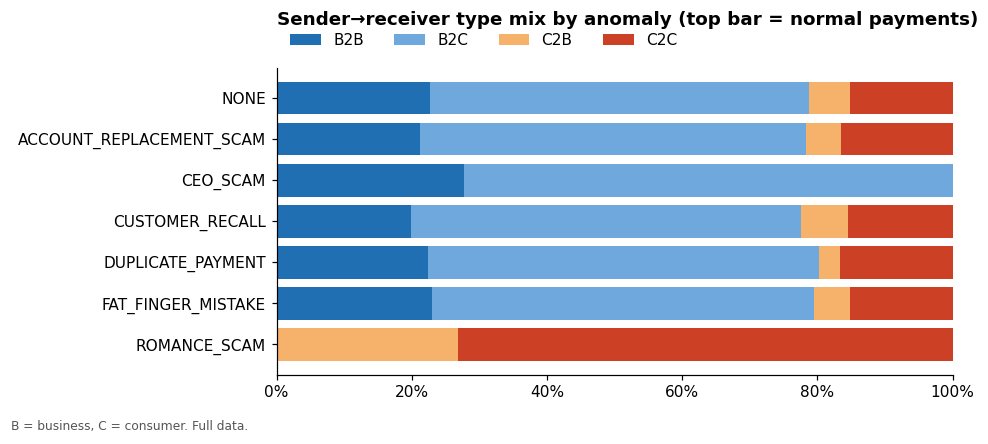

In [27]:
# A-1: sender->receiver pair mix of each anomaly vs normal payments
mix = q("SELECT anomaly, pair, count(*) AS n FROM p GROUP BY ALL")
mix = mix.pivot(index="anomaly", columns="pair", values="n").fillna(0)
mix = mix.div(mix.sum(axis=1), axis=0)
mix = mix.loc[["NONE"] + [i for i in mix.index if i != "NONE"]]
fig, ax = plt.subplots(figsize=(9, 4))
left = np.zeros(len(mix))
for col, colr in zip(mix.columns, ["#1F6FB2", "#6FA8DC", "#F6B26B", "#CC4125"]):
    ax.barh(mix.index, mix[col], left=left, color=colr, label=col); left += mix[col].values
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(ncol=4, bbox_to_anchor=(0, 1.02), loc="lower left", frameon=False)
ax.set_title("Sender→receiver type mix by anomaly (top bar = normal payments)", pad=28)
finish(fig, "A1_pair_mix_by_anomaly", "B = business, C = consumer. Full data.")

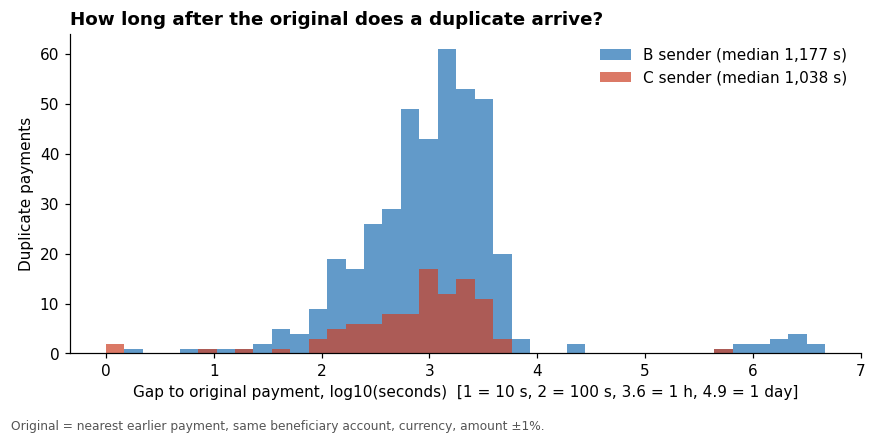

In [28]:
# A-2: duplicate gap distribution by sender type
g = q("SELECT ORDERING_TYPE AS sender_type, gap_s FROM dup_match")
if len(g):
    fig, ax = plt.subplots(figsize=(8, 4))
    bins = np.linspace(0, np.log10(g.gap_s.max() + 1) + 0.1, 40)
    for t, colr in [("B", HI), ("C", "#CC4125")]:
        s = g[g.sender_type == t].gap_s
        if len(s):
            ax.hist(np.log10(s + 1), bins=bins, alpha=.7, color=colr, label=f"{t} sender (median {s.median():,.0f} s)")
    ax.set_xlabel("Gap to original payment, log10(seconds)  [1 = 10 s, 2 = 100 s, 3.6 = 1 h, 4.9 = 1 day]")
    ax.set_ylabel("Duplicate payments"); ax.legend(frameon=False)
    ax.set_title("How long after the original does a duplicate arrive?")
    finish(fig, "A2_duplicate_gap", "Original = nearest earlier payment, same beneficiary account, currency, amount ±1%.")

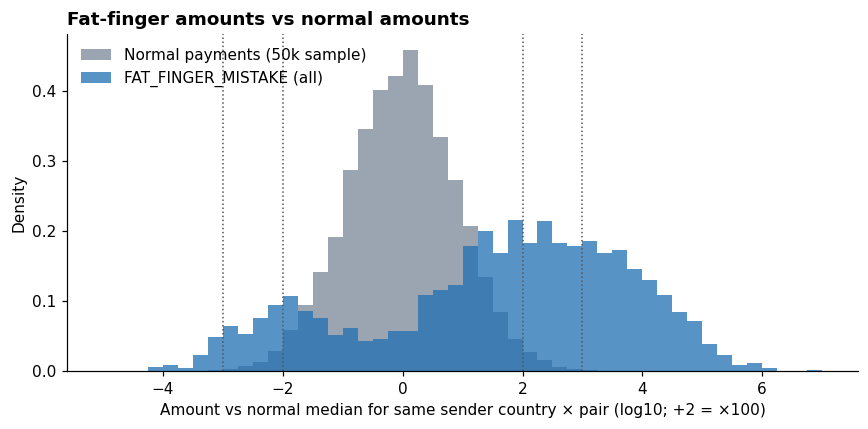

In [29]:
# A-3: fat-finger amount shift vs normal
s = q("""
SELECT anomaly = 'FAT_FINGER_MISTAKE' AS ff, log10(USD_AMOUNT) - b.med_log10 AS sh
FROM (SELECT * FROM p WHERE anomaly = 'FAT_FINGER_MISTAKE'
      UNION ALL SELECT * FROM (SELECT * FROM p WHERE anomaly='NONE') USING SAMPLE reservoir(50000 ROWS) REPEATABLE (42)) x
JOIN amt_base b USING (o_cc, pair) WHERE USD_AMOUNT > 0""")
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(np.floor(s.sh.min()), np.ceil(s.sh.max()) + 0.25, 0.25)
ax.hist(s[~s.ff].sh, bins=bins, density=True, color=BASE, label="Normal payments (50k sample)")
ax.hist(s[s.ff].sh, bins=bins, density=True, color=HI, alpha=.75, label="FAT_FINGER_MISTAKE (all)")
for k in (-3, -2, 2, 3):
    ax.axvline(k, ls=":", c=GREY, lw=1)
ax.set_xlabel("Amount vs normal median for same sender country × pair (log10; +2 = ×100)")
ax.set_ylabel("Density"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Fat-finger amounts vs normal amounts")
finish(fig, "A3_fatfinger_shift")

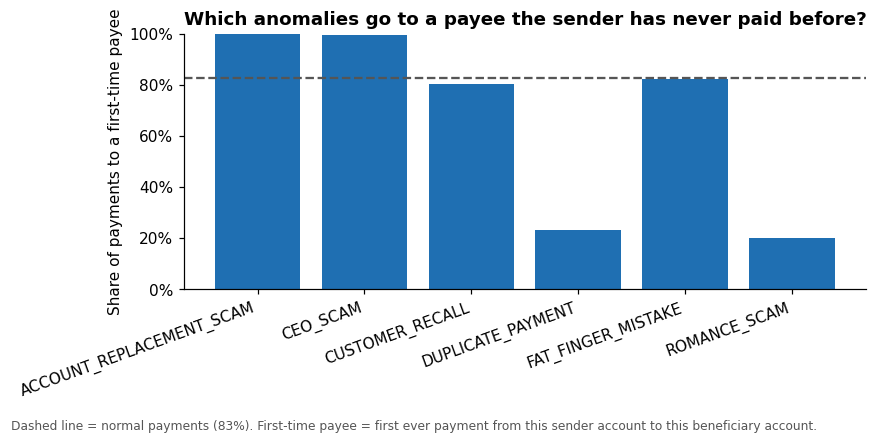

In [30]:
# A-4: first-time payee share by anomaly vs normal (baseline line)
pf = prof.set_index("grp")
base = pf.loc["NONE (all)", "first_time_payee"]
an = pf.drop(index=[i for i in pf.index if i.startswith("NONE")])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(an.index, an.first_time_payee, color=HI)
ax.axhline(base, ls="--", c=GREY)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Share of payments to a first-time payee"); plt.xticks(rotation=20, ha="right")
ax.set_title("Which anomalies go to a payee the sender has never paid before?")
finish(fig, "A4_first_time_payee", f"Dashed line = normal payments ({base:.0%}). First-time payee = first ever payment from this sender account to this beneficiary account.")

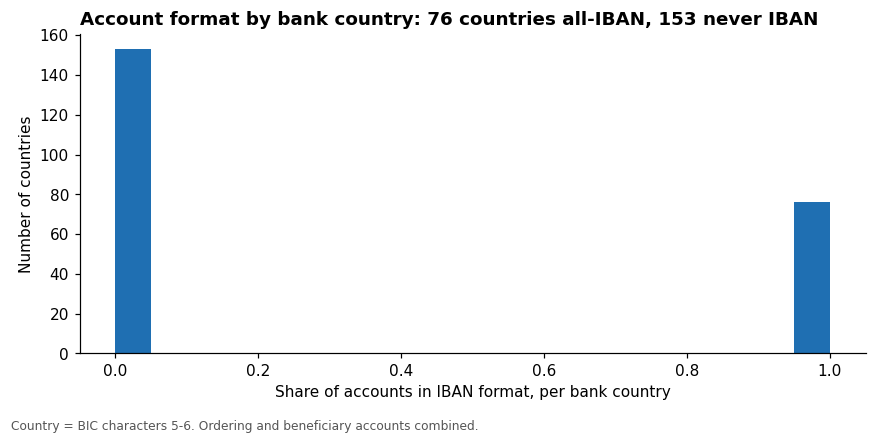

In [31]:
# AC-1: IBAN share per bank country is all-or-nothing?
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(iban_cc.iban_share, bins=20, color=HI)
ax.set_xlabel("Share of accounts in IBAN format, per bank country"); ax.set_ylabel("Number of countries")
ax.set_title(f"Account format by bank country: {(iban_cc.iban_share > .99).sum()} countries all-IBAN, "
             f"{(iban_cc.iban_share < .01).sum()} never IBAN")
finish(fig, "AC1_iban_share_by_country", "Country = BIC characters 5-6. Ordering and beneficiary accounts combined.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

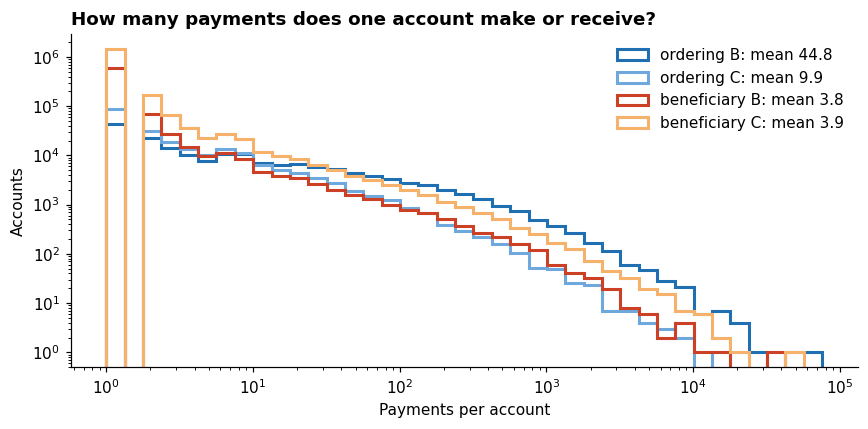

In [32]:
# AC-2: payments per account, by role x party type
acts = q("""SELECT role, typ, n, count(*) AS accounts
            FROM (SELECT role, typ, acct, count(*) AS n FROM acct_long2 GROUP BY ALL) GROUP BY ALL""")
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(0, np.log10(acts.n.max() + 1), 40)
for (r, t), colr in zip([("ordering", "B"), ("ordering", "C"), ("beneficiary", "B"), ("beneficiary", "C")],
                        [HI, "#6FA8DC", "#CC4125", "#F6B26B"]):
    g = acts[(acts.role == r) & (acts.typ == t)]
    if len(g):
        mean = (g.n * g.accounts).sum() / g.accounts.sum()
        ax.hist(g.n, bins=bins, weights=g.accounts, histtype="step", lw=2, color=colr, label=f"{r} {t}: mean {mean:.1f}")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Payments per account"); ax.set_ylabel("Accounts")
ax.legend(frameon=False); ax.set_title("How many payments does one account make or receive?")
finish(fig, "AC2_payments_per_account")

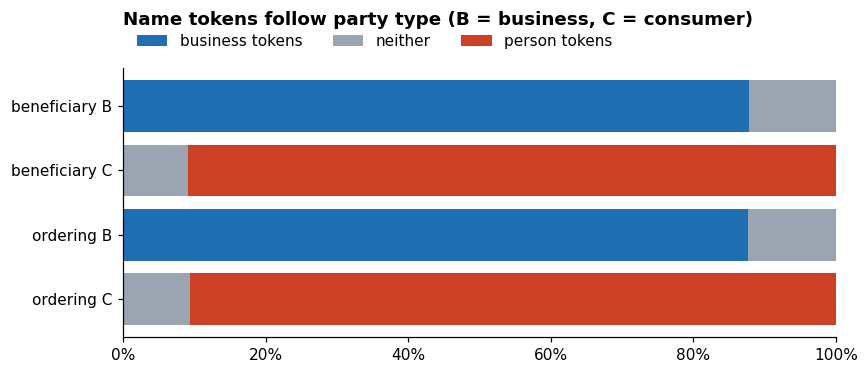

In [33]:
# D-1: name token class vs party type
piv = nc.pivot_table(index=["side", "typ"], columns="name_class", values="share").fillna(0)
fig, ax = plt.subplots(figsize=(8, 3.5))
left = np.zeros(len(piv)); labels = [f"{s} {t}" for s, t in piv.index]
for col, colr in zip(piv.columns, [HI, BASE, "#CC4125"]):
    ax.barh(labels, piv[col], left=left, color=colr, label=col); left += piv[col].values
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.invert_yaxis()
ax.legend(ncol=3, bbox_to_anchor=(0, 1.02), loc="lower left", frameon=False)
ax.set_title("Name tokens follow party type (B = business, C = consumer)", pad=28)
finish(fig, "D1_name_tokens_by_party_type")

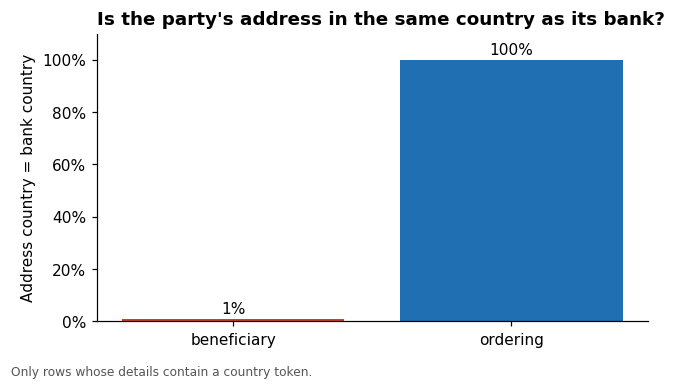

In [34]:
# D-2: address country = bank country, sender vs receiver
dd = det.groupby("side").apply(lambda g: np.average(g.addr_country_eq_bank.fillna(0), weights=g.n * g.has_country), include_groups=False)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(dd.index, dd.values, color=[HI if i == "ordering" else "#CC4125" for i in dd.index])
for i, v in enumerate(dd.values):
    ax.text(i, v + .02, f"{v:.0%}", ha="center")
ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Address country = bank country")
ax.set_title("Is the party's address in the same country as its bank?")
finish(fig, "D2_address_vs_bank_country", "Only rows whose details contain a country token.")

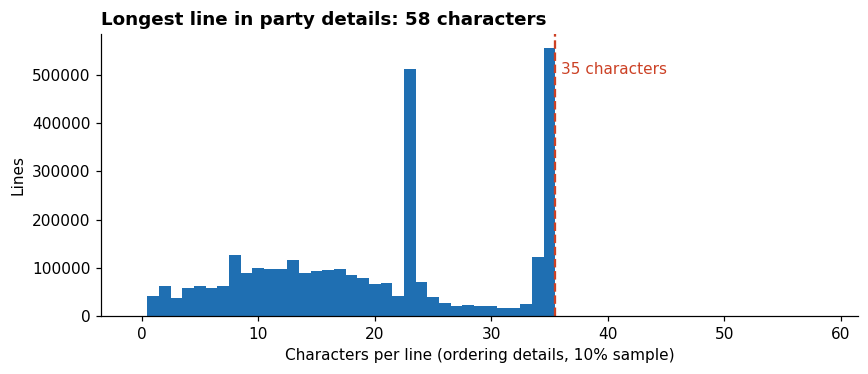

In [35]:
# D-3: line-length ceiling
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(linelen.line_len, linelen.n, color=HI, width=1)
ax.axvline(35.5, ls="--", c="#CC4125"); ax.text(36, linelen.n.max() * .9, "35 characters", color="#CC4125")
ax.set_xlabel("Characters per line (ordering details, 10% sample)"); ax.set_ylabel("Lines")
ax.set_title(f"Longest line in party details: {int(linelen.line_len.max())} characters")
finish(fig, "D3_line_length")

## 8. Rules log
Write one row per rule **after** reading the tables above. Keep the template: condition → effect → size → scope → exceptions, then Observed / Interpretation / Rejected / Confidence. This file feeds the dashboards and slides.

In [36]:
RULES_COLS = ["id", "group", "when_condition", "then_effect", "size", "scope_rows_pct", "exceptions",
              "observed_evidence_table_or_chart", "interpretation_real_world", "rejected_alternative", "confidence"]
rules_path = TAB / "rules_log.csv"
if not rules_path.exists():
    pd.DataFrame([{
        "id": "A2-example", "group": "Anomalies",
        "when_condition": "Payment labelled DUPLICATE_PAYMENT and sender is a business",
        "then_effect": "An earlier payment exists with same sender, beneficiary, currency and amount",
        "size": "median gap = ?? s", "scope_rows_pct": "?? of ?? duplicates (??%)",
        "exceptions": "C senders: different sender account (partner) and longer gap?",
        "observed_evidence_table_or_chart": "a_duplicates_vs_control.csv; A2_duplicate_gap.png",
        "interpretation_real_world": "INTERPRETATION: back-office race condition re-submits the same payment",
        "rejected_alternative": "Exact copy of the row (rejected: timestamps differ)",
        "confidence": "High / Med / Low"}], columns=RULES_COLS).to_csv(rules_path, index=False)
pd.read_csv(rules_path)

,id,group,when_condition,then_effect,size,scope_rows_pct,exceptions,observed_evidence_table_or_chart,interpretation_real_world,rejected_alternative,confidence
0,A2-example,Anomalies,Payment labelled DUPLICATE_PAYMENT and sender ...,"An earlier payment exists with same sender, be...",median gap = ?? s,?? of ?? duplicates (??%),C senders: different sender account (partner) ...,a_duplicates_vs_control.csv; A2_duplicate_gap.png,INTERPRETATION: back-office race condition re-...,Exact copy of the row (rejected: timestamps di...,High / Med / Low
